# CAVE six-class pre+post: all folds

This analysis reads saved final reports and epoch caches through the frozen report catalog. It produces **equal-weight means across five folds**, with **pointwise 95% Student-t confidence intervals** (four degrees of freedom). Folds, not individual windows, are the uncertainty unit. The training sets overlap across folds, so these intervals describe fold variability; they are not independent-replicate or untouched-test confidence guarantees.

No five-fold summary is drawn for an incomplete group. Learning curves use only epochs present in all five folds. Paired differences are computed within each fold before averaging. Confusion matrices average **row-normalized matrices**, rather than pooling windows; each cell displays its mean and CI half-width. Unsupported class rows are marked rather than treated as zero accuracy.

Whole-cell analyses retain the historical eight-class hierarchy and 5 µm Euclidean nucleus exclusion. Density analyses use **six-class morpho labels at confidence ≥0.7**, with bins 32/16/8/4 and 9/17/33/65 nodes. Historical mesh-skeleton comparisons retain their five neuronal classes. V1DD models select epochs using **MICrONS validation-window macro F1 only**, while preserving separate MICrONS, V1DD, and combined final results. The paired axon/dendrite experiment retains its separate inner validation split; other historical experiments select on the reported held-out fold.

Source analysis: `analysis/presynaptic/cave_skeletons_pre_post/six_class/gt_pre_post.ipynb`. The original version, where present, is archived under `analysis/report_folds_20261012/legacy_notebooks/`. These pages cover the report's registered models; historical mixed-batch pilots are retained in that archive rather than mixed into the report comparison.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
from IPython.display import display
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'scripts/train_gnn.py').exists())
sys.path.insert(0,str(root/'analysis/report_folds_20261012'))
import all_folds as af
cache=af.load('CAVE six-class pre+post',family=None,model='GT')
display(cache['status'][['label','completed_folds','complete']])


,label,completed_folds,complete
0,GT / pre_post,"[0, 1, 2, 3, 4]",True


## Window and cell performance
Mean across folds with 95% fold confidence intervals.

,label,domain,scope,metric,mean,ci_low,ci_high,folds
0,GT / pre_post,Combined,window,accuracy,0.857291,0.824377,0.890205,5
1,GT / pre_post,Combined,window,balanced_accuracy,0.697534,0.658478,0.736591,5
2,GT / pre_post,Combined,window,macro_precision,0.718609,0.674865,0.762354,5
3,GT / pre_post,Combined,window,macro_f1,0.701579,0.678379,0.724779,5
4,GT / pre_post,Combined,cell,accuracy,0.946431,0.936405,0.956458,5
5,GT / pre_post,Combined,cell,balanced_accuracy,0.819488,0.733341,0.905636,5
6,GT / pre_post,Combined,cell,macro_precision,0.947868,0.929698,0.966039,5
7,GT / pre_post,Combined,cell,macro_f1,0.847807,0.777087,0.918526,5


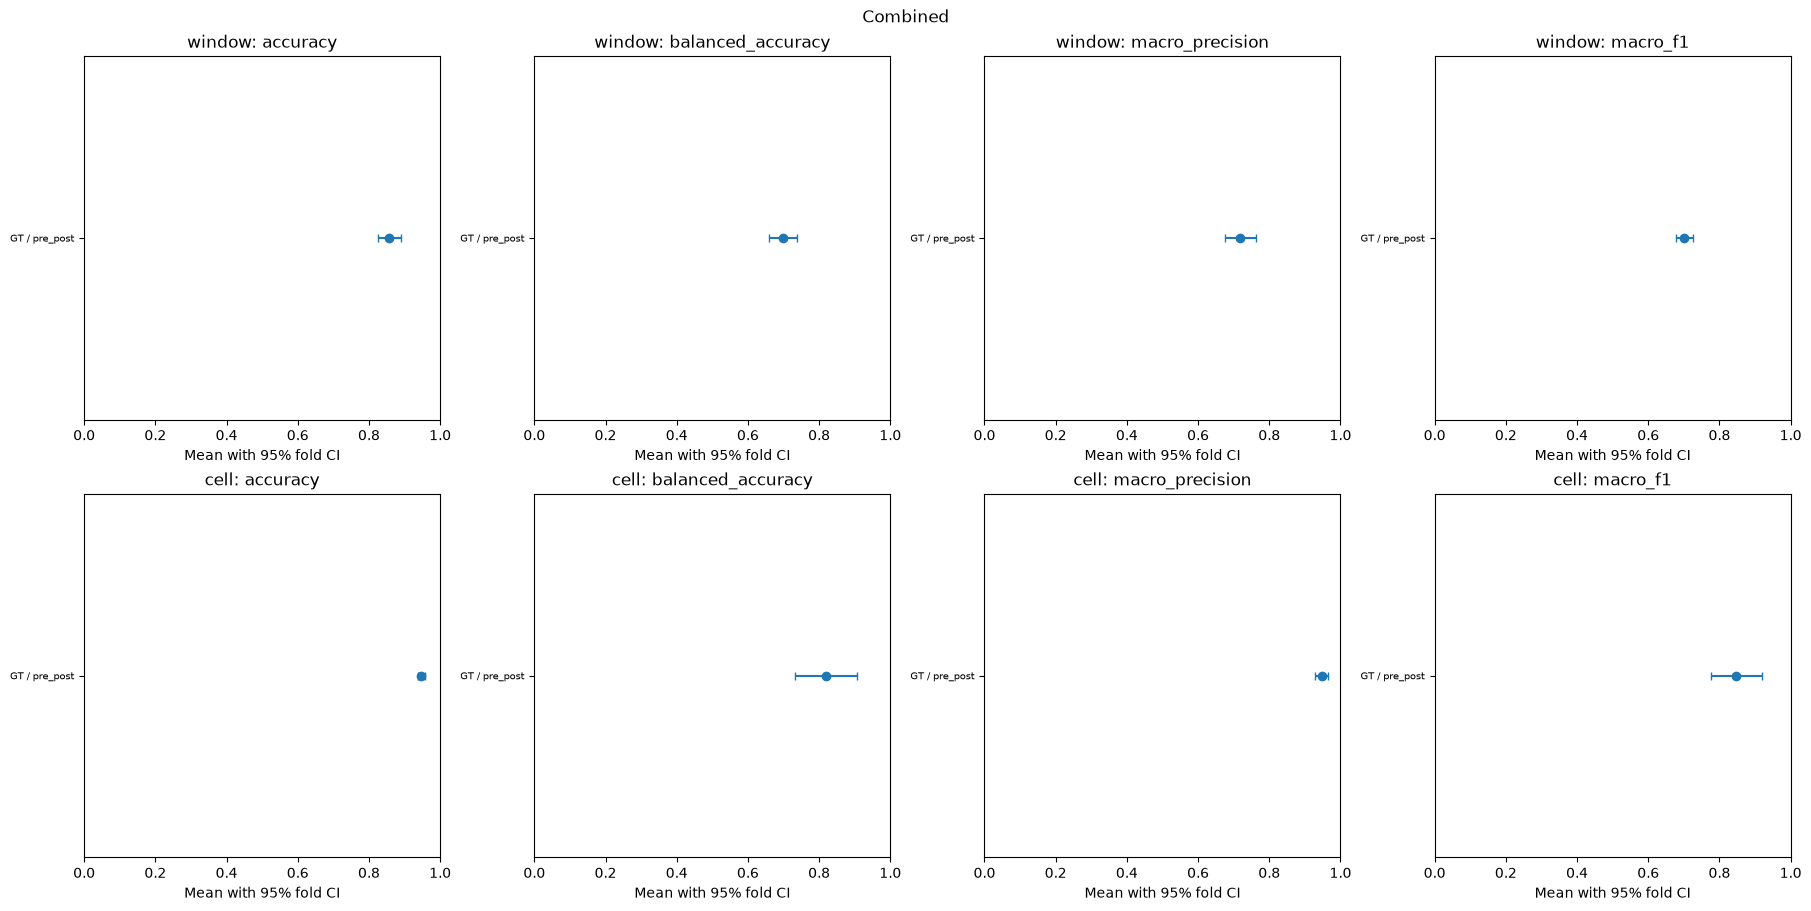

In [2]:
display(af.summary(cache))
af.plot_scores(cache)

## Cohort composition
For confidence sweeps: mean source-manifest cell counts and 95% fold CIs. Entire-cohort counts are identical across folds, so their intervals have zero width. These counts precede window eligibility filtering.

In [3]:
af.plot_cohort_counts(cache)

## Confidence / density trends
Five-fold mean with shaded 95% fold CI, where applicable.

In [4]:
af.plot_trends(cache)

## Training progress
Mean curve and shaded 95% fold CI; no individual-fold overlays.

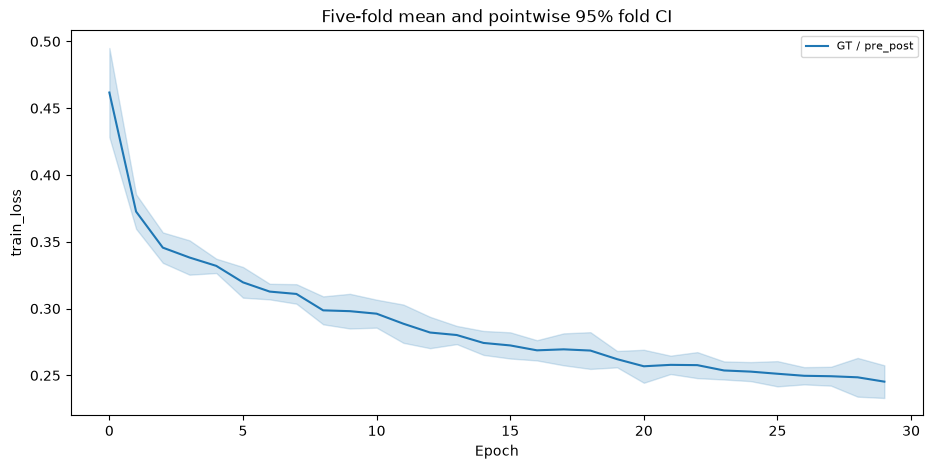

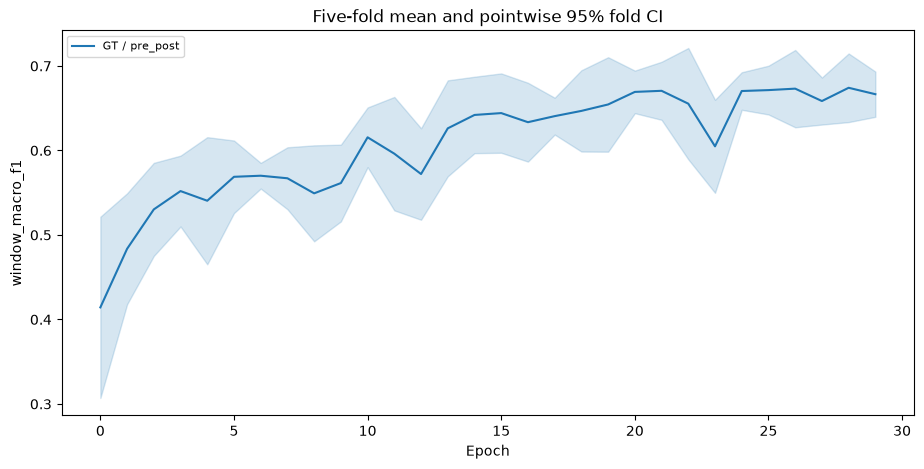

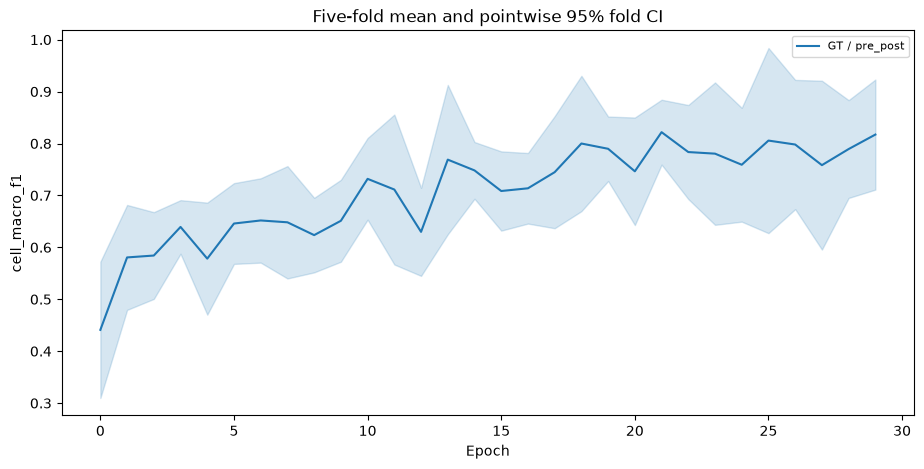

In [5]:
af.plot_curves(cache)

## Paired changes
Within-fold differences with 95% fold CI.

In [6]:
af.plot_deltas(cache)

## Class recall, precision, and support
Means and shaded 95% fold CIs.

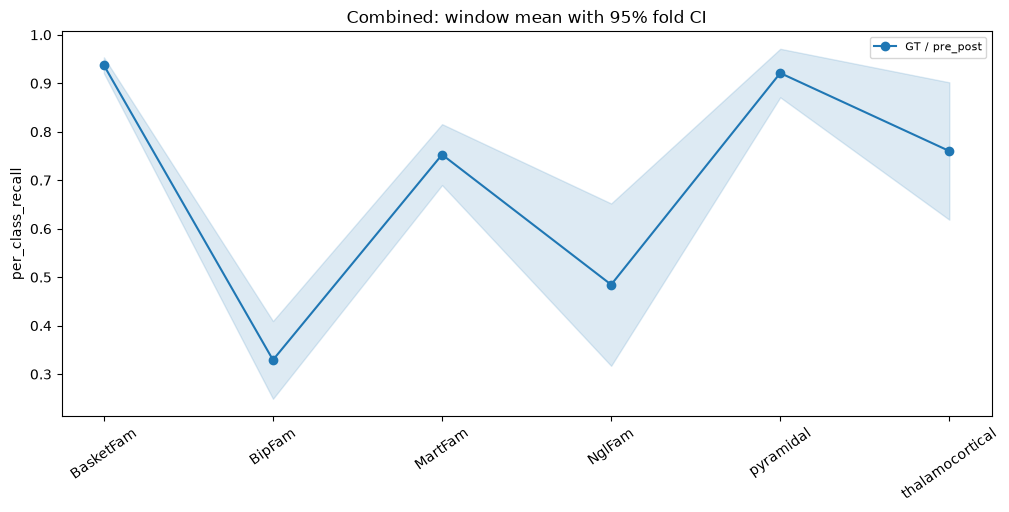

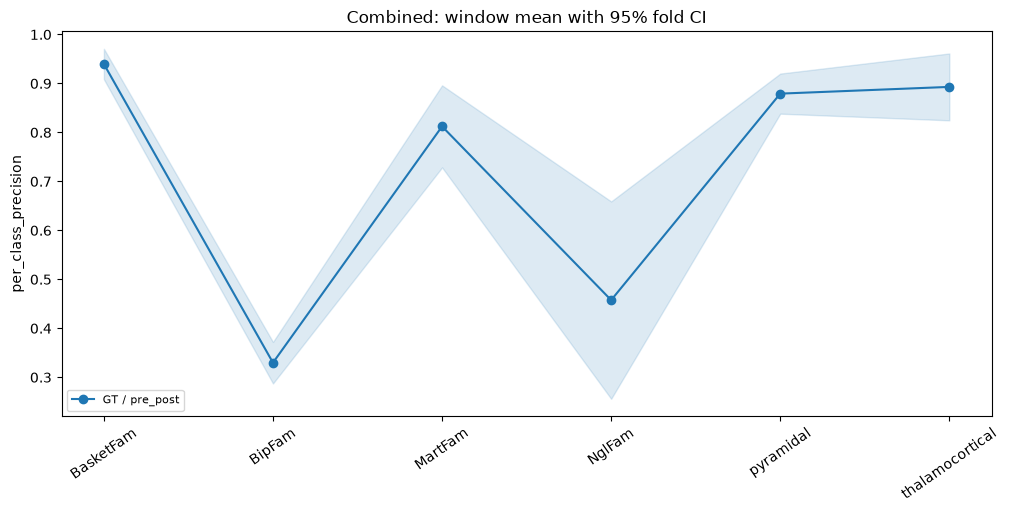

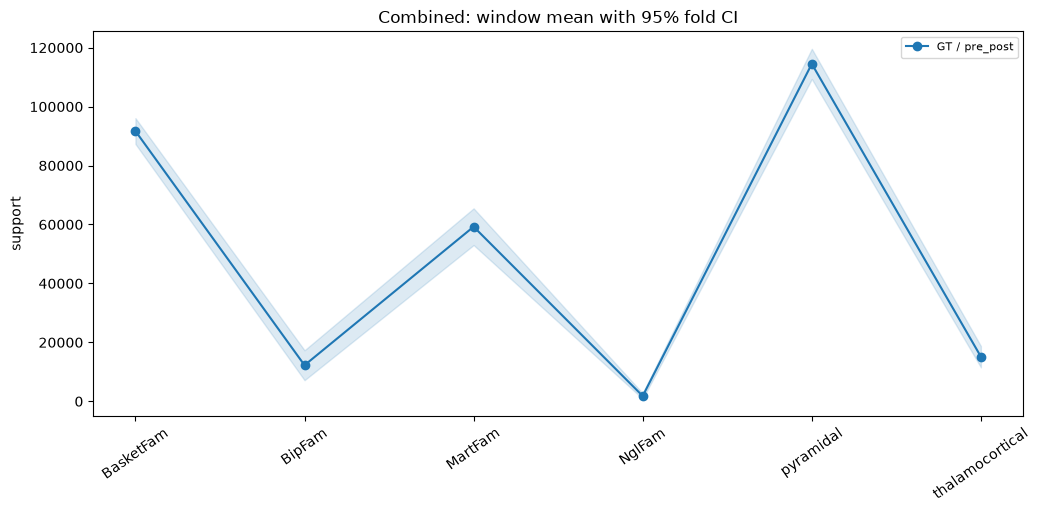

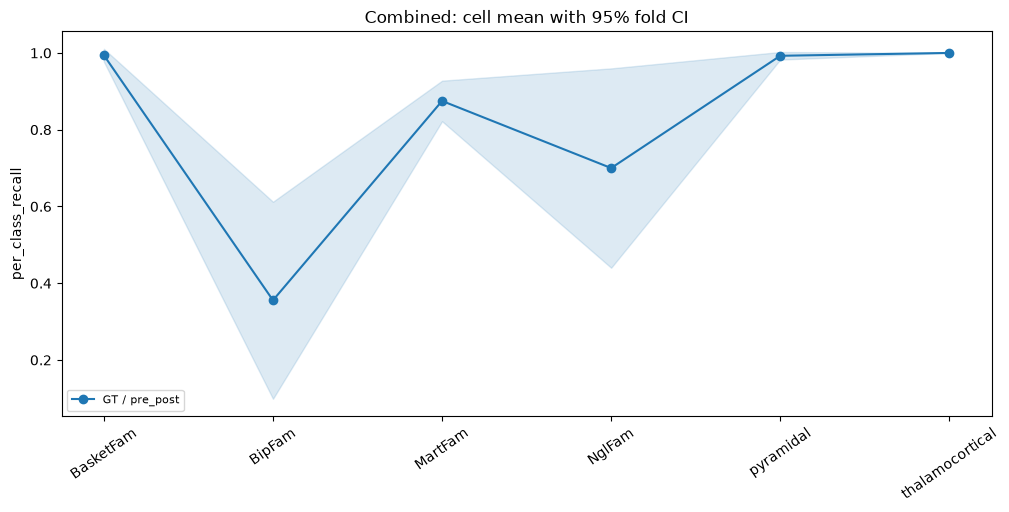

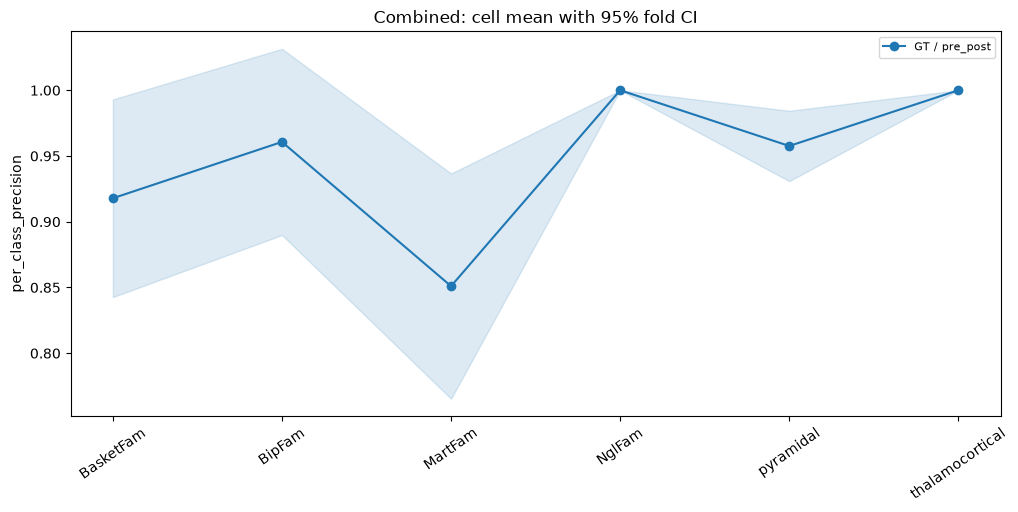

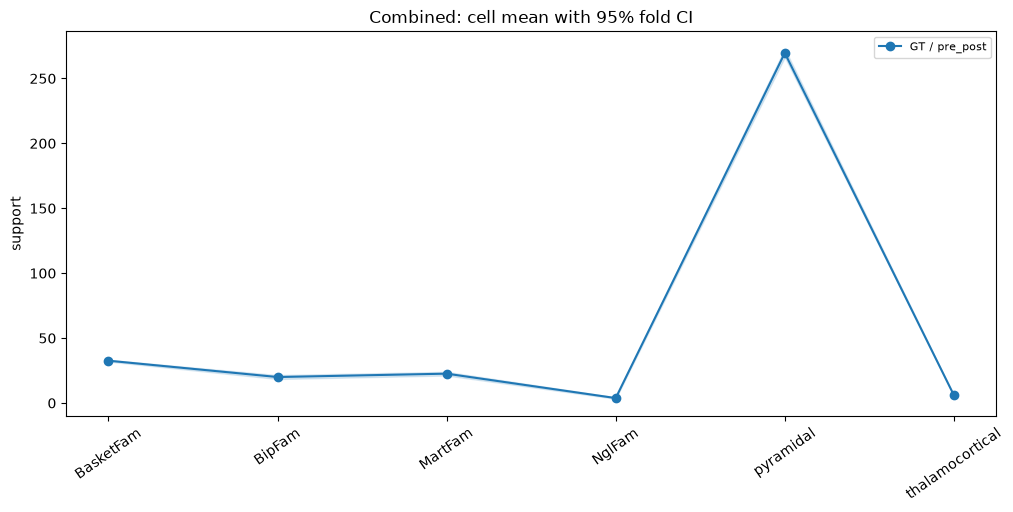

In [7]:
af.plot_classes(cache)

## Confusion matrices
Equal fold-weighted normalized confusion matrices, with 95% fold CI per cell.

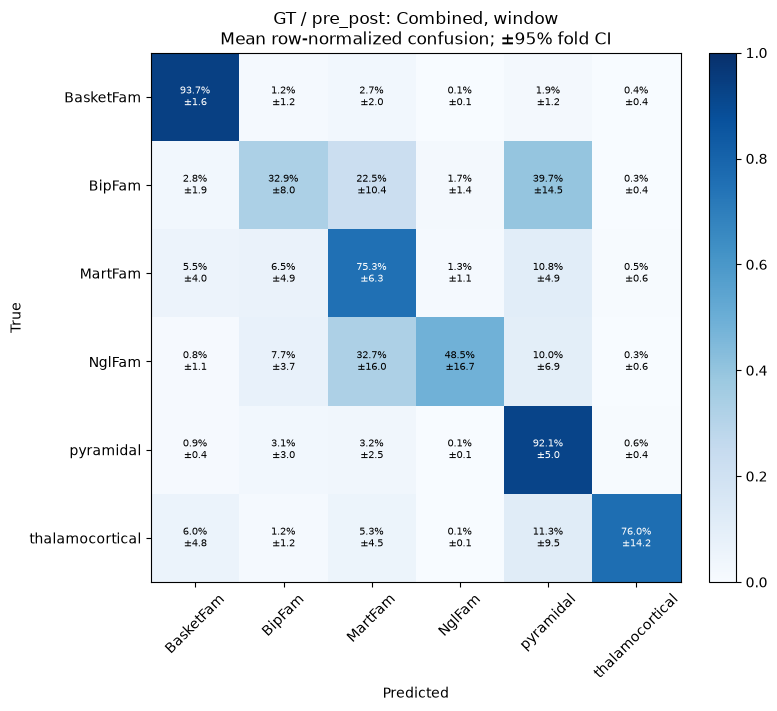

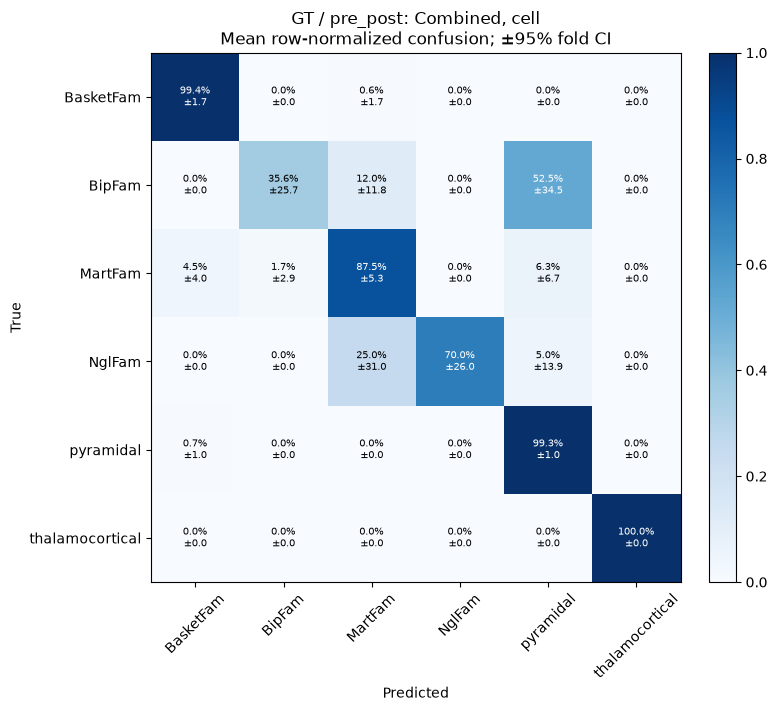

In [8]:
af.plot_confusions(cache)